In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 2/4/2022
# version ='1.0'

# Demo: Solving Equality Constrained Analytic Center By Infeasible Start Newton Method - 2 : Infeasible or Unbounded Problem

In the text book book-convex-2004, section 10.3, the infeasible start Newton method was used to solve the equality constrained analytic center problem,
$$
\begin{array}{rcl}
\mathbf{miniminze} & & f(x)=-\displaystyle{\sum_{i=1}^{n}}\log x_i \\
\mathbf{subject to} & & Ax = b\\ 
\end{array}
$$
where $A \in R^{m\times n}$, with implicit constraint $x\succ 0$.

Depending on $A, b$, the problem could be infeasible or unbounded. This demo is to review the behaviour of the infeasible start Newton method for either infeasible or unbounded problems.

The problem is infeasible when \textbf{dom} $f=\{x|x\succ 0\}$ does not intersect $\{x|Ax=b\}$. According to the \textbf{Theorems of alternative}:

The problem: $$\{x|Ax=b, x\succeq 0\}$$ is infeasible if and only if its alternative problem: $$\{\nu | \nu^T b \prec 0, A^T\nu \succeq 0\}$$ is feasible. So one can randomly generate $(A, b, \nu)$ until they are feasible in the alternative problem.

To make the problem unbounded below, $A, b$ can be generated in the following way:

\begin{enumerate}
\item Randomly select $a_0\in R^n_{++}$
\item Select $m$ basis $a_1, a_2, ..., a_m$ from the null space of $a_0$, i.e. $\mathcal{N}(a_0)$, and let $A=\left[
\begin{array}{c}
a_1^T \\
a_2^T \\
... \\
a_m^T
\end{array}
\right]$. In this way, $Aa_0=0$
\item Randomly select $x_o\in R^n_{++}$, and let $b=Ax_o$
\end{enumerate}

In this way, $\{x|Ax=b\}\supset \{x_o+\beta a_0, \beta\in R_{++} \}$. When $\beta\rightarrow \infty$, $f(x)$ is unbounded below.

In [2]:
import numpy as np
import sys
import matplotlib.pyplot as plt
from scipy.linalg import null_space

$f(x)=-\sum_{i=1}^n\log x_i$

$\nabla f(x)=\dfrac{1}{x}$

$\nabla^2 f(x)= diag(\dfrac{1}{x^2})$

it requires $x\succ 0$

In [3]:
def my_f(x):
    """
    $f(x)=-\sum_{i=1}^n\log x_i$
    :param x:
    :return:
    """
    return -np.sum(np.log(x))


def my_derivative_f(x):
    """
    $\nabla f(x)=\dfrac{1}{x}$
    :param x:
    :return:
    """
    return -1 / x


def my_hessian_f(x):
    """
    $\nabla^2 f(x)= diag(\dfrac{1}{x^2})$
    :param x:
    :return:
    """
    return np.diag(1 / (np.squeeze(x) ** 2))


def my_f_feasible(x):
    """
    it requires $x\succ 0$
    :param x:
    :return:
    """
    return np.all(x > 0)

calculate the primal-dual step by solving the KKT equations
    $$
    \begin{array}{rccl}
    \left[\begin{array}{cc}
    \nabla^2 f(x) & A^T \\
    A & 0 \\
     \end{array}
     \right] &
     \left[\begin{array}{c}
      \Delta x_{pd} \\
      \Delta \nu_{pv}
     \end{array}
     \right] &
     = &
     -\left[
       \begin{array}{c}
        r_{dual} \\
        r_{pri} \\
       \end{array}
      \right]
    \end{array}
    $$
 where
    $r_{dual}=\nabla f(x)+A^Tx$, $r_{pri}=Ax-b$

In [4]:
def primal_dual_newton_step(x, nu, A, b):
    """
    calculate the primal-dual step by solving the KKT equations
    $$
    \begin{array}{rccl}
    \left[\begin{array}{cc}
    \nabla^2 f(x) & A^T \\
    A & 0 \\
     \end{array}
     \right] &
     \left[\begin{array}{c}
      \Delta x_{pd} \\
      \Delta \nu_{pv}
     \end{array}
     \right] &
     = &
     -\left[
       \begin{array}{c}
        r_{dual} \\
        r_{pri} \\
       \end{array}
      \right]
    \end{array}
    $$
    where
    $r_{dual}=\nabla f(x)+A^Tx$, $r_{pri}=Ax-b$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    KKT_matrix = np.block([[my_hessian_f(x), A.T], [A, np.zeros((A.shape[0], A.shape[0]))]])
    minus_residual_dual_primal = -1 * np.block([[my_derivative_f(x) + (A.T @ nu)], [A @ x - b]])
    if np.linalg.cond(KKT_matrix) < 1 / sys.float_info.epsilon:
        newton_step = np.linalg.inv(KKT_matrix) @ minus_residual_dual_primal
        primal_step = newton_step[0: len(x)]
        dual_step = newton_step[len(x):]
        return True, primal_step, dual_step
    else:
        #raise RuntimeError("KKT matrix is not invertible.")
        return False, None, None

$r=\left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right]$

$|r_{pri}|, |r_{dual}|$

$|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2$

In [5]:
def residual_f(x, nu, A, b):
    """
    $r=\left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right]$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    r_dual = my_derivative_f(x) + A.T @ nu
    r_pri = A @ x - b
    return np.block([[r_dual], [r_pri]])


def residual_dual_primal_norm_f(x, nu, A, b):
    """
    $|r_{pri}|, |r_{dual}|$
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    residual = residual_f(x, nu, A, b)
    return np.linalg.norm(residual[0: len(x)]), np.linalg.norm(residual[len(x):])


def residual_norm_f(x, nu, A, b):
    """
    $|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2
    $
    :param x:
    :param nu:
    :param A:
    :param b:
    :return:
    """
    residual = residual_f(x, nu, A, b)
    return np.linalg.norm(residual)

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [6]:
def backtracking_line_search(x, nu, d_x, d_nu, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param x:
    :param nu:
    :param d_x:
    :param d_nu:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    t = 1
    r = residual_norm_f
    while (not my_f_feasible(x + d_x * t)) \
            or r(x + t * d_x, nu + t * d_nu, *args) > (1 - alpha * t) * r(x, nu, *args):
        t = beta * t
    return t

Get parameters for an infeasible model within a maximum of dials

Refer to FlexibleLecture Note for more detail

In [7]:
def get_infeasible_model_parameters(m, n, seed, max_dial=100):
    """
    get parameters for an infeasible model within a maximum of dials
    Refer to FlexibleLecture Note for more detail
    :param seed:
    :param n:
    :param m:
    :param max_dial:
    :return:
    """
    np.random.seed(seed)
    n_trial = 0
    while True:
        A = np.random.uniform(-1, 1, (m, n))
        v = np.random.uniform(-1, 1, (m, 1))
        b = np.random.uniform(-1, 1, (m, 1))
        if (v.T @ b < 0) and (np.all(A.T @ v) >= 0):
            return True, A, b
        else:
            n_trial = n_trial + 1
            if n_trial >= max_dial:
                raise RuntimeError("Can not generate infeasible A, b?")
    return False, None, None

Get parameters for a feasible model

Refer to FlexibleLecture Note for more detail

In [8]:
def get_feasible_model_parameters(m, n, seed):
    """
    get parameters for a feasible model
    Refer to FlexibleLecture Note for more detail
    :param seed:
    :param n:
    :param m:
    :return:
    """
    np.random.seed(seed)
    A = np.random.rand(m, n)
    nu_asterisk = np.random.rand(m, 1)
    inv_x_asterisk = A.T @ nu_asterisk
    x_asterisk = 1 / inv_x_asterisk
    b = A @ x_asterisk
    return A, b, nu_asterisk, x_asterisk

Get parameters for an unbounded model

Refer to FlexibleLecture Note for more detail

In [9]:
def get_unbounded_model_parameters(m, n, seed):
    """
    get parameters for an unbounded model
    Refer to FlexibleLecture Note for more detail
    :param n:
    :param m:
    :param seed:
    :return:
    """
    np.random.seed(seed)
    a0 = np.random.rand(1, n)
    orth_a0 = null_space(a0)
    if not np.allclose(a0 @ orth_a0, 0):
        raise RuntimeError('the null space of a0 should exist!')
    A_T = orth_a0[:, 0: m]
    A = A_T.T
    x_asterisk = np.random.rand(n, 1)
    b = A @ x_asterisk
    x0 = 100 * np.random.rand(n, 1)
    if np.allclose(b - A @ x0, 0):
        raise RuntimeError('It is to simulate infeasible start Newton method')
    nu0 = np.zeros((m, 1))
    return A, b, x0, nu0, x_asterisk

plot the convergence graph in solving equality constraint problem by the infeasible start method

In [10]:
def plot_infeasible_start_newton_method_convergence(A, b, x0, nu0, max_iteration=100):
    """
    plot the convergence graph in solving equality constraint problem by the infeasible start method
    :param A:
    :param b:
    :param x0:
    :param nu0:
    :param max_iteration:
    :return:
    """
    alpha = 0.01
    beta = 0.5
    epsilon = 1e-12
    zeta = 1e-12

    x = x0
    nu = nu0
    args = (A, b)
    iteration = 0

    r_dual_norms = []
    r_prim_norms = []
    step_lengths = []
    while True:
        r_dual_norm, r_prim_norm = residual_dual_primal_norm_f(x, nu, A, b)
        success, d_x, d_nu = primal_dual_newton_step(x, nu, A, b)
        if not success:
            break
        t = backtracking_line_search(x, nu, d_x, d_nu, alpha, beta, args)
        x = x + t * d_x
        nu = nu + t * d_nu
        iteration = iteration + 1

        # logging
        r_dual_norms.append(r_dual_norm)
        r_prim_norms.append(r_prim_norm)
        step_lengths.append(t)
        #print('Info: iteration={}, |r_pri|={}, |r_dual|={}'.format(iteration, r_dual_norm, r_prim_norm))

        r_pri = np.linalg.norm(A @ x - b)
        r_dual = residual_norm_f(x, nu, A, b)
        if r_pri < zeta and r_dual <= epsilon:
            break

        if iteration >= max_iteration:
            break

    r_dual_norm, r_prim_norm = residual_dual_primal_norm_f(x, nu, A, b)
    r_dual_norms.append(r_dual_norm)
    r_prim_norms.append(r_prim_norm)

    ax = plt.subplot(1, 2, 1)
    ax.semilogy(r_prim_norms, marker='+', label=r'$\parallel r_{pri} \parallel$')
    ax.semilogy(r_dual_norms, marker='x', label=r'$\parallel r_{dual} \parallel$')
    ax.legend()
    ax.grid()
    ax.set_xlabel('iteration')
    ax.set_ylabel('residual')

    ax = plt.subplot(1, 2, 2)
    ax.plot(step_lengths, marker='+', label='t: step length')
    ax.legend()
    ax.grid()
    ax.set_xlabel('iteration')
    ax.set_ylabel('t: step length')
    plt.show()

In [11]:
def plot_convergence_if_infeasible(m, n, seed):
    success, A, b = get_infeasible_model_parameters(n=n, m=m, seed=seed, max_dial=100)
    if not success:
        print('Error: not able to get infeasible model parameters at the maximum dials')
        return

    x0 = np.ones((n, 1))
    nu0 = np.zeros((m, 1))
    plot_infeasible_start_newton_method_convergence(A=A, b=b, x0=x0, nu0=nu0)

In [12]:
def plot_convergence_if_feasible(m, n, seed):
    A, b, _, _ = get_feasible_model_parameters(n=n, m=m, seed=seed)
    x0 = np.ones((n, 1))
    nu0 = np.zeros((m, 1))
    plot_infeasible_start_newton_method_convergence(A=A, b=b, x0=x0, nu0=nu0)

In [13]:
def plot_convergence_if_unbounded(n, m, seed):
    A, b, x0, nu0, x_asterisk = get_unbounded_model_parameters(n=n, m=m, seed=seed)
    plot_infeasible_start_newton_method_convergence(A=A, b=b, x0=x0, nu0=nu0)

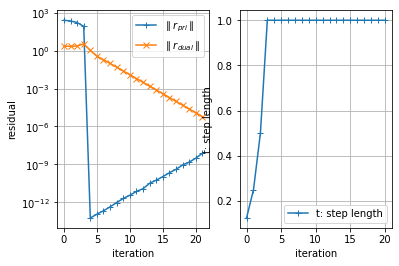

In [14]:
if __name__ == "__main__":
    plot_convergence_if_unbounded(n=100, m=50, seed=2)

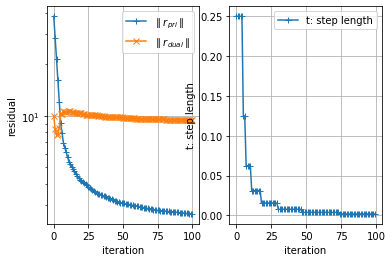

In [15]:
if __name__ == "__main__":
    plot_convergence_if_infeasible(n=100, m=50, seed=2)

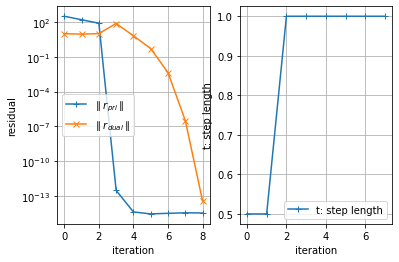

In [16]:
if __name__ == "__main__":
    plot_convergence_if_feasible(n=100, m=50, seed=2)